## **South African Commercial Accommodations Sector: A Post-COVID-19 Recovery Analysis (2021-2026).**   

##### The main objective of this analysis is to get insight into how different commercial accommodations have performed in income post-COVID-19. 

### **Data Acquisition** 

In [1]:
#I started by importing the necessary libraries for this analysis
import pandas as pd
import numpy as np

In [2]:
filepath = "tourist_accommodation.csv"

In [3]:
#I then read the dataset using pandas.
df = pd.read_csv(filepath)

In [4]:
#Checked the first 5 rows of the dataset.
df.head(5)

,date,metric,category,series_type,price_basis,unit,value,series_code
0,2007-01-01,Income from accommodation,Caravan parks and camping sites,Actual figures,Current prices,R million,10.2,E64102
1,2007-02-01,Income from accommodation,Caravan parks and camping sites,Actual figures,Current prices,R million,7.9,E64102
2,2007-03-01,Income from accommodation,Caravan parks and camping sites,Actual figures,Current prices,R million,10.2,E64102
3,2007-04-01,Income from accommodation,Caravan parks and camping sites,Actual figures,Current prices,R million,11.8,E64102
4,2007-05-01,Income from accommodation,Caravan parks and camping sites,Actual figures,Current prices,R million,7.4,E64102


In [5]:
#Checked the last 5 rows of the dataset.
df.tail(5)

,date,metric,category,series_type,price_basis,unit,value,series_code
17545,2026-02-01,Total income,Total industry,Seasonally adjusted,Current prices,R million,6212.1,TOT_TOT_D11
17546,2026-03-01,Total income,Total industry,Seasonally adjusted,Current prices,R million,6328.8,TOT_TOT_D11
17547,2026-04-01,Total income,Total industry,Seasonally adjusted,Current prices,R million,6298.6,TOT_TOT_D11
17548,2026-05-01,Total income,Total industry,Seasonally adjusted,Current prices,R million,6394.2,TOT_TOT_D11
17549,2026-06-01,Total income,Total industry,Seasonally adjusted,Current prices,R million,6272.8,TOT_TOT_D11


In [6]:
#Since the analysis focuses on the years 2021 to 2026, I had to ensure that Python recognises the 'date' column as dates. 
df['date'] = pd.to_datetime(df['date'])

In [7]:
#This code ensures that the date shown in the data is between 2021 and 2026.
df = df[(df['date'].dt.year >= 2021) & (df['date'].dt.year <= 2026)]

In [8]:
#I had to confirm if the code was successful, and if it shows 2021 to 2026.
df['date'].dt.year.unique()

array([2021, 2022, 2023, 2024, 2025, 2026], dtype=int32)

In [9]:
#Checked the data types.
df.dtypes
print(df.dtypes)

date           datetime64[us]
metric                    str
category                  str
series_type               str
price_basis               str
unit                      str
value                 float64
series_code               str
dtype: object


In [10]:
#Checked the statistical summary of the data.
df.describe()

,date,value
count,4950,4950.000000
mean,2023-09-16 04:00:00,804.212263
min,2021-01-01 00:00:00,0.000000
25%,2022-05-01 00:00:00,41.525000
50%,2023-09-16 00:00:00,169.250000
75%,2025-02-01 00:00:00,1268.450000
max,2026-06-01 00:00:00,6962.400000
std,NaN,1134.496246


In [11]:
#Let's check the structure of the dataframe
df.info()

<class 'pandas.DataFrame'>
Index: 4950 entries, 168 to 17549
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         4950 non-null   datetime64[us]
 1   metric       4950 non-null   str           
 2   category     4950 non-null   str           
 3   series_type  4950 non-null   str           
 4   price_basis  3300 non-null   str           
 5   unit         4950 non-null   str           
 6   value        4950 non-null   float64       
 7   series_code  4950 non-null   str           
dtypes: datetime64[us](1), float64(1), str(6)
memory usage: 757.1 KB


### **Data Wrangling**

In [12]:
#Checked for Null values.
df.isnull().sum()

date              0
metric            0
category          0
series_type       0
price_basis    1650
unit              0
value             0
series_code       0
dtype: int64

In [13]:
#Checked precisely where the Null values in the 'price_basis' are coming from.
df[df['price_basis'].isnull()]['metric'].unique()

<ArrowStringArray>
['Occupancy rate', 'Stay units available', 'Stay units nights sold']
Length: 3, dtype: str

In [14]:
#Will have to fill the NaN in the column with 'Not Applicable'
df['price_basis'] = df['price_basis'].fillna('Not Applicable')

In [15]:
#Let's confirm if our code went through.
df['price_basis'].value_counts(dropna=False)

price_basis
Current prices    3300
Not Applicable    1650
Name: count, dtype: int64

In [16]:
#We notice in the data that the column 'series_type' has 'Actual figures'and 'seasonally adjusted', which would create duplicates if left like that, so a decision has to be made to drop one.
df['series_type'].value_counts()

series_type
Actual figures         2640
Seasonally adjusted    2310
Name: count, dtype: int64

In [17]:
#For analysis purposes and correlation, we decided to keep 'actual figures', since 'seasonally adjusted' doesn't cover all categories, and to avoid duplicates.
df = df[df['series_type'] == 'Actual figures']
df = df.drop(columns=['series_type'])

In [18]:
#Now we will check for duplicates.
df.duplicated().sum()

np.int64(0)

In [19]:
#We will check for inconsistencies in metric.
df['metric'].unique()

<ArrowStringArray>
[           'Income from accommodation',
 'Income from restaurant and bar sales',
     'Income per stay unit nights sold',
                       'Occupancy rate',
                         'Other income',
                 'Stay units available',
               'Stay units nights sold',
                         'Total income']
Length: 8, dtype: str

In [20]:
#Now we will check for inconsistencies in the category.
df['category'].unique()

<ArrowStringArray>
['Caravan parks and camping sites',    'Guest houses and guest farms',
                          'Hotels',             'Other accommodation',
                  'Total industry']
Length: 5, dtype: str

In [41]:
#Decided to remove 'Total industry' as it's just the sum of the four categories.
df = df[df['category'] != 'Total industry']
df['category'].unique()

<ArrowStringArray>
['Caravan parks and camping sites',    'Guest houses and guest farms',
                          'Hotels',             'Other accommodation']
Length: 4, dtype: str

In [42]:
df.to_csv('accommodation_clean.csv', index=False)

In [22]:
#With all the changes, we will check the 'price_basis' values.
df['price_basis'].value_counts()

price_basis
Current prices    1320
Not Applicable     792
Name: count, dtype: int64

In [23]:
#Now we will check the shape of the table
df.shape
df.head()

,date,metric,category,price_basis,unit,value,series_code
168,2021-01-01,Income from accommodation,Caravan parks and camping sites,Current prices,R million,45.8,E64102
169,2021-02-01,Income from accommodation,Caravan parks and camping sites,Current prices,R million,27.4,E64102
170,2021-03-01,Income from accommodation,Caravan parks and camping sites,Current prices,R million,44.7,E64102
171,2021-04-01,Income from accommodation,Caravan parks and camping sites,Current prices,R million,68.2,E64102
172,2021-05-01,Income from accommodation,Caravan parks and camping sites,Current prices,R million,47.7,E64102


In [24]:
#Checking the last rows of the table before analysis.
df.tail()

,date,metric,category,price_basis,unit,value,series_code
16843,2026-02-01,Total income,Other accommodation,Current prices,R million,1501.7,H64109
16844,2026-03-01,Total income,Other accommodation,Current prices,R million,1744.9,H64109
16845,2026-04-01,Total income,Other accommodation,Current prices,R million,1635.4,H64109
16846,2026-05-01,Total income,Other accommodation,Current prices,R million,1438.2,H64109
16847,2026-06-01,Total income,Other accommodation,Current prices,R million,1433.7,H64109


### **Data Analysis**

In [25]:
#We will import sqlite and create a database file named 'accommodations' and a connection. 
import sqlite3
conn = sqlite3.connect('accommodations.db')

In [26]:
#We will now push the df into an SQL table.
df.to_sql('accommodations', conn, if_exists='replace', index=False)

2112

In [27]:
#We will run our first query to check if our SQL is working well.
query = """
SELECT * FROM accommodations
LIMIT 5"""
pd.read_sql(query, conn)

,date,metric,category,price_basis,unit,value,series_code
0,2021-01-01 00:00:00,Income from accommodation,Caravan parks and camping sites,Current prices,R million,45.8,E64102
1,2021-02-01 00:00:00,Income from accommodation,Caravan parks and camping sites,Current prices,R million,27.4,E64102
2,2021-03-01 00:00:00,Income from accommodation,Caravan parks and camping sites,Current prices,R million,44.7,E64102
3,2021-04-01 00:00:00,Income from accommodation,Caravan parks and camping sites,Current prices,R million,68.2,E64102
4,2021-05-01 00:00:00,Income from accommodation,Caravan parks and camping sites,Current prices,R million,47.7,E64102


In [28]:
#Accommodation category performance over the period (2021-2026Jun)
query = """
SELECT category, unit, SUM(value) AS Total_by_category
FROM accommodations
WHERE metric = 'Income from accommodation'
GROUP BY category
ORDER BY Total_by_category DESC"""
category_income = pd.read_sql(query, conn)
category_income

,category,unit,Total_by_category
0,Hotels,R million,97449.5
1,Other accommodation,R million,64051.2
2,Guest houses and guest farms,R million,8464.6
3,Caravan parks and camping sites,R million,3710.0


In [29]:
#Accommodation category yearly income performance (2021-2026Jun).
query = """
SELECT strftime('%Y', date) AS year, category, SUM(value) AS Total_by_year
FROM accommodations
WHERE metric = 'Total income'
GROUP BY year, category
ORDER BY year ASC, Total_by_year DESC"""

yearly = pd.read_sql(query, conn)
yearly

,year,category,Total_by_year
0,2021,Hotels,20145.4
1,2021,Other accommodation,8131.2
2,2021,Guest houses and guest farms,1306.9
3,2021,Caravan parks and camping sites,640.1
4,2022,Hotels,38480.0
5,2022,Other accommodation,10948.0
6,2022,Guest houses and guest farms,2004.7
7,2022,Caravan parks and camping sites,643.2
8,2023,Hotels,45838.5
9,2023,Other accommodation,14575.0


In [30]:
#Top Three months across all four categories (2021Jan-2026Jun). 
query = """
SELECT strftime('%m', date) AS month, ROUND(AVG(value),2) AS Average_occupancy
FROM accommodations
WHERE metric = 'Occupancy rate'
GROUP BY month
ORDER BY Average_occupancy DESC
LIMIT 3"""
busiest = pd.read_sql(query, conn)
busiest

,month,Average_occupancy
0,12,36.34
1,10,34.83
2,09,34.52


In [31]:
# Overall accommodation occupancy rate by category (2021-2026Jun).
query = """
SELECT category, ROUND(AVG(value),2) AS Average_occupancy
FROM accommodations
WHERE metric = 'Occupancy rate'
GROUP BY category
ORDER BY Average_occupancy DESC"""

occupancy = pd.read_sql(query, conn)
occupancy

,category,Average_occupancy
0,Hotels,46.37
1,Caravan parks and camping sites,29.84
2,Other accommodation,29.62
3,Guest houses and guest farms,23.95


In [32]:
#Market share by category over the period (2021-2026Jun).
query = """
SELECT category,
ROUND(SUM(value) * 100.0 / (SELECT SUM(value) FROM accommodations WHERE metric = 'Total income'), 2) AS market_share_pct
FROM accommodations
WHERE metric = 'Total income'
GROUP BY category
ORDER BY market_share_pct DESC"""

market_share = pd.read_sql(query, conn)
market_share

,category,market_share_pct
0,Hotels,71.31
1,Other accommodation,24.13
2,Guest houses and guest farms,3.33
3,Caravan parks and camping sites,1.24


#### **Correlation**

In [33]:
#Created a pivot table for Occupancy rate and Total income for correlation purposes.
pivot = df[df['metric'].isin(['Occupancy rate', 'Total income'])].pivot_table(index=['date', 'category'], columns='metric', values='value').reset_index()

pivot.head()

metric,date,category,Occupancy rate,Total income
0,2021-01-01,Caravan parks and camping sites,23.4,48.4
1,2021-01-01,Guest houses and guest farms,16.7,90.0
2,2021-01-01,Hotels,16.3,864.3
3,2021-01-01,Other accommodation,22.2,538.2
4,2021-02-01,Caravan parks and camping sites,24.2,27.4


In [34]:
#Analysed the correlation between Occupancy and income per accommodation category. 
pivot.groupby('category')[['Occupancy rate', 'Total income']].corr()

metric                                          Occupancy rate  Total income
category                        metric                                      
Caravan parks and camping sites Occupancy rate        1.000000      0.728259
                                Total income          0.728259      1.000000
Guest houses and guest farms    Occupancy rate        1.000000      0.767323
                                Total income          0.767323      1.000000
Hotels                          Occupancy rate        1.000000      0.973243
                                Total income          0.973243      1.000000
Other accommodation             Occupancy rate        1.000000      0.817632
                                Total income          0.817632      1.000000

## **Data Visualization.**

In [35]:
#We will start by importing visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

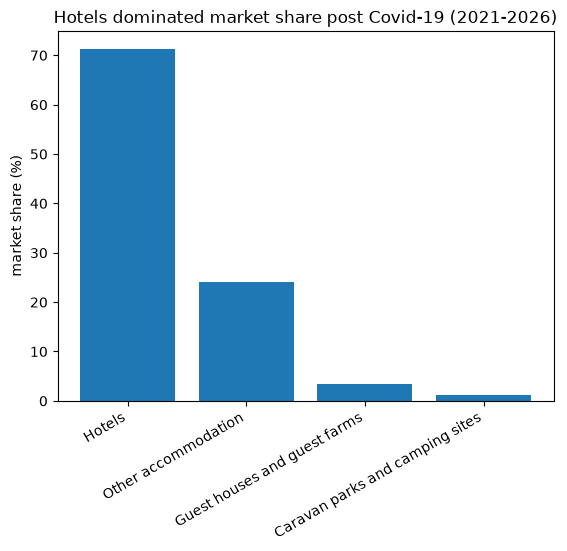

In [36]:
# Let's create a bar chart to compare market share by accommodation category post COVID-19.
plt.bar(market_share['category'], market_share['market_share_pct'])
plt.title('Hotels dominated market share post Covid-19 (2021-2026)')
plt.ylabel('market share (%)')
plt.xticks(rotation=30, ha='right')
plt.show()


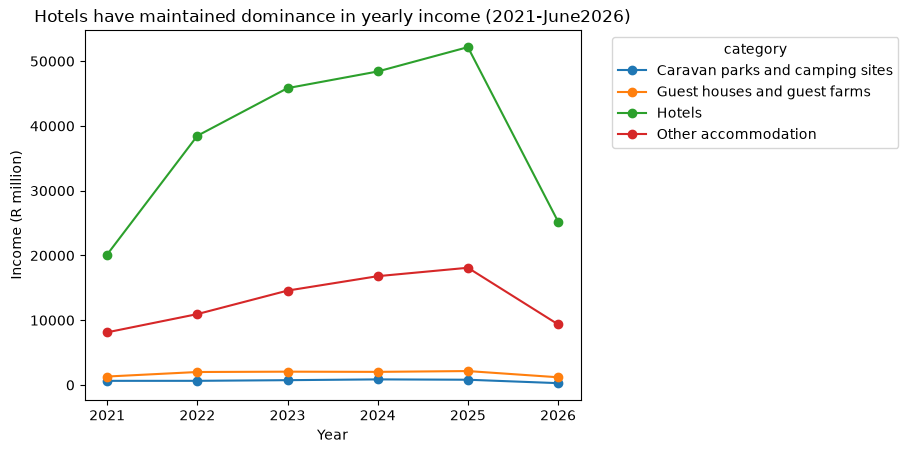

In [37]:
#A line chart showing yearly income by accommodation category from 2021 to June 2026 (Reason for the dip in 2026).
pivot_yearly = yearly.pivot(index='year', columns='category', values='Total_by_year')
pivot_yearly.plot(kind='line', marker='o')
plt.title('Hotels have maintained dominance in yearly income (2021-June2026)')
plt.ylabel('Income (R million)')
plt.xlabel('Year')
plt.legend(title='category', bbox_to_anchor=(1.05,1), loc='upper left')
plt.show()

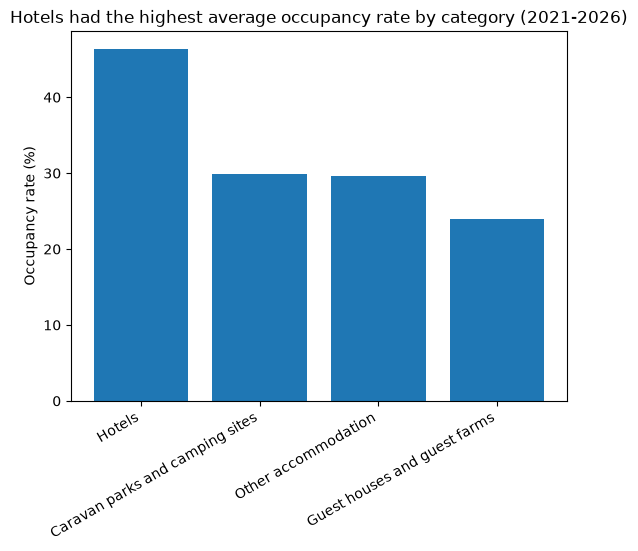

In [38]:
#A bar chart showing average occupancy rate by accommodation category from 2021 to 2026.
plt.bar(occupancy['category'], occupancy['Average_occupancy'])
plt.title('Hotels had the highest average occupancy rate by category (2021-2026)')
plt.ylabel('Occupancy rate (%)')
plt.xticks(rotation=30, ha='right')
plt.show()

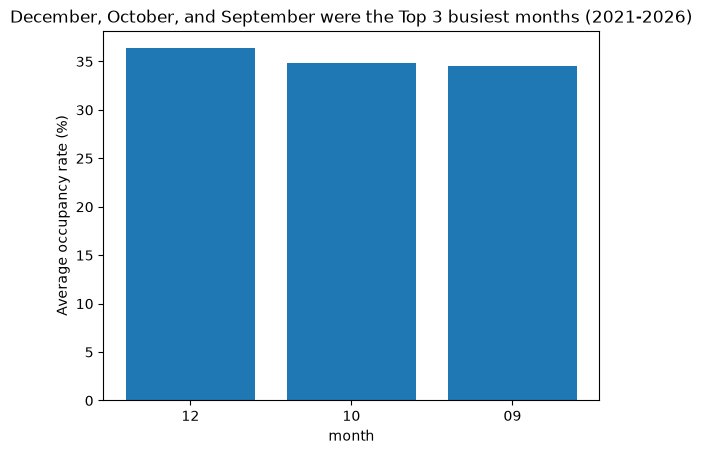

In [39]:
# A bar chart showing seasonality (Top 3 busiest months) across the four categories (2021-2026).
plt.bar(busiest['month'], busiest['Average_occupancy'])
plt.title('December, October, and September were the Top 3 busiest months (2021-2026)')
plt.xlabel('month')
plt.ylabel('Average occupancy rate (%)')
plt.show()

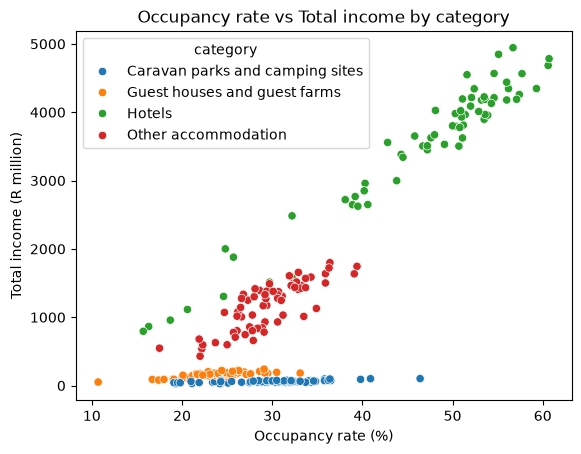

In [40]:
#A scatter plot showing the relationship between occupancy and income across the four accommodation categories (2021-2026).
sns.scatterplot(data=pivot, x='Occupancy rate', y='Total income', hue='category')
plt.title('Occupancy rate vs Total income by category')
plt.xlabel('Occupancy rate (%)')
plt.ylabel('Total income (R million)')
plt.show()

## **Conclusion**

##### **1. Hotels dominated, with 71.31% of total income and the highest occupancy (46.37%).**
##### **2. December, October, and September were the busiest months.**
##### **3. Occupancy and income are strongly correlated across all categories (correlation: 0.97).**
##### **4. 2026 covers January to June only.**